# File 2: Rental Analysis (Auckland)

## Purpose
Rent is the one measure with real history: MBIE bond data by SA2, quarterly, back to 1993. This notebook turns it into
rent levels, rent growth over 1, 5 and 10 years, rent by dwelling type and bedrooms, and affordability against census income.

## Inputs
| File | What |
|---|---|
| `data/clean/master_flagged.csv` | From File 1: one row per SA2 with flags. Rankings use `analysis_ready` SA2s only |
| `data/clean/rent_timeseries_by_sa2.csv` | Quarterly median rent and active bonds by SA2 (all dwellings) |
| `data/rental/mbie_quarterly_sa2_2020_2026.csv` | Raw MBIE file, used for the dwelling-type and bedroom split |

## Two things to keep in mind
- **Shared rent.** 142 SA2s take their rent from an MBIE (2018) source SA2 that another SA2 also uses (`rent_source_sa2`,
  `flag_borrowed_rent`). When averaging across SA2s, each source area must count once, not once per child, or split areas are over-weighted.
- **"Auckland" figures here are bond-weighted averages of SA2 medians.** A median of medians is an approximation, not MBIE's official regional median.

## Steps
1. Load data and check the rent series
2. Rent growth over 1, 5 and 10 years
3. Maps: rent level and 5-year change
4. Did cheaper areas catch up? (rent bands over time)
5. Rent by dwelling type and bedrooms, and 3-bedroom house rent by SA2
6. Affordability: rent against household income
7. Save outputs

## Outputs
- `data/clean/rent_metrics_by_sa2.csv`: one row per SA2 with growth, 3-bed house rent and affordability
- `data/clean/rent_by_type_sa2.csv`: one row per SA2 x dwelling type x bedrooms: rent, quarters with a figure, lowest and
  highest quarterly median, new bonds lodged over the 4 quarters, active bonds, `flag_thin_sample`, `flag_unstable_rent`,
  `data_note` (Tenancy Services' one-bedroom warning)
- `visualizations/02_*.png`

In [1]:
# STEP 0: SETUP
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, NullFormatter

CLEAN = Path('data/clean')
VIZ = Path('visualizations'); VIZ.mkdir(exist_ok=True)

# Palette: categorical slots 1-2, single-hue sequential, orange-grey-blue diverging
BLUE, ORANGE, GREY, INK, MUTED = '#2a78d6', '#eb6834', '#b9b8b3', '#0b0b0b', '#52514e'
SEQ = 'Blues'
DIV = LinearSegmentedColormap.from_list('div', [ORANGE, '#e6e5e1', BLUE])
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GREY, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'grid.color': '#ecebe8', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'font.size': 10,
})
dollars = FuncFormatter(lambda v, _: f'${v/1e6:.1f}m' if v >= 1e6 else f'${v/1e3:.0f}k')
CV_TICKS = [1e5, 3e5, 5e5, 1e6, 2e6, 5e6, 1e7, 3e7]

def cv_axis(ax, lo, hi):
    ax.set_xscale('log'); ax.set_xticks([t for t in CV_TICKS if lo <= t <= hi])
    ax.xaxis.set_major_formatter(dollars); ax.xaxis.set_minor_formatter(NullFormatter())
pd.set_option('display.width', 160, 'display.max_columns', 40)

### Step 1: Load data and check the rent series

In [2]:
# STEP 1: LOAD DATA AND CHECK THE RENT SERIES
m = pd.read_csv(CLEAN / 'master_flagged.csv')
rent_ts = pd.read_csv(CLEAN / 'rent_timeseries_by_sa2.csv', parse_dates=['quarter'])
geo = gpd.read_file('data/boundaries/auckland_sa2_2023.geojson')
geo['sa2_code'] = geo['SA22023_V1_00'].astype(int)
latest = rent_ts.quarter.max()

# One SA2 per MBIE source SA2, so a split 2018 area is counted once in Auckland-wide averages
unique_rent_sa2 = m.loc[m.median_rent_weekly.notna() & ~m.duplicated('rent_source_sa2'), 'sa2_code']
ts_unique = rent_ts[rent_ts.sa2_code.isin(unique_rent_sa2)]

print(f'Latest quarter: {latest:%B %Y} | SA2s with any rent history: {rent_ts.sa2_code.nunique()} | with a current figure: {m.median_rent_weekly.notna().sum()}')
print(f'Distinct rent areas after removing borrowed duplicates: {len(unique_rent_sa2)}')

# How complete is the last 10 years? MBIE leaves a quarter blank when too few bonds were lodged
last10 = rent_ts[rent_ts.quarter > latest - pd.DateOffset(years=10)]
q = last10.groupby('sa2_code').size()
print(f'Quarters with a figure in the last 10 years (out of 40): median {q.median():.0f}, '
      f'SA2s with all 40: {(q == 40).sum()}, with fewer than 30: {(q < 30).sum()}')

Latest quarter: July 2026 | SA2s with any rent history: 616 | with a current figure: 600
Distinct rent areas after removing borrowed duplicates: 527
Quarters with a figure in the last 10 years (out of 40): median 40, SA2s with all 40: 468, with fewer than 30: 53


### Step 2: Rent growth over 1, 5 and 10 years

In [3]:
# STEP 2: RENT GROWTH. Each point = mean of the 4 quarters ending N years before the latest quarter (smooths quarterly noise)
def window_mean(years_back):
    end = latest - pd.DateOffset(years=years_back)
    w = rent_ts[(rent_ts.quarter > end - pd.DateOffset(years=1)) & (rent_ts.quarter <= end)]
    return w.groupby('sa2_code').median_rent.mean()

now = window_mean(0)
g = pd.DataFrame({f'rent_{n}y_ago': window_mean(n) for n in [1, 5, 10]})
for n in [1, 5, 10]:
    g[f'rent_change_{n}y_pct'] = 100 * (now / g[f'rent_{n}y_ago'] - 1)
g['rent_cagr_10y_pct'] = 100 * ((now / g.rent_10y_ago) ** (1 / 10) - 1)
master_5y = m.pop('rent_change_5y_pct')
m = m.join(g, on='sa2_code')

# Same method as build_master.py, so current rent and 5-year change must match the master file
assert np.allclose(m.sa2_code.map(now), m.median_rent_weekly, atol=0.01, equal_nan=True)
assert np.allclose(m.rent_change_5y_pct, master_5y, atol=0.01, equal_nan=True)

ready = m[m.analysis_ready]
growth = ['rent_change_1y_pct', 'rent_change_5y_pct', 'rent_change_10y_pct', 'rent_cagr_10y_pct']
print('Rent change across analysis-ready SA2s (%):')
ready[growth].describe(percentiles=[.1, .5, .9]).round(1)

Rent change across analysis-ready SA2s (%):


,rent_change_1y_pct,rent_change_5y_pct,rent_change_10y_pct,rent_cagr_10y_pct
count,581.0,581.0,583.0,583.0
mean,0.6,13.2,35.4,3.0
std,6.3,12.1,15.2,1.1
min,-33.0,-38.6,-30.8,-3.6
10%,-5.6,3.1,19.9,1.8
50%,0.0,12.3,34.8,3.0
90%,8.0,24.5,51.5,4.2
max,31.1,140.1,134.3,8.9


In [4]:
c = ['sa2_name', 'rent_5y_ago', 'median_rent_weekly', 'rent_change_5y_pct', 'active_bonds', 'flag_borrowed_rent']
r5 = ready.dropna(subset=['rent_change_5y_pct']).drop_duplicates('rent_source_sa2')
print('Fastest and slowest 5-year rent growth (borrowed duplicates shown once):')
pd.concat([r5.nlargest(10, 'rent_change_5y_pct')[c], r5.nsmallest(10, 'rent_change_5y_pct')[c]]).round(1)

Fastest and slowest 5-year rent growth (borrowed duplicates shown once):


,sa2_name,rent_5y_ago,median_rent_weekly,rent_change_5y_pct,active_bonds,flag_borrowed_rent
178,Ōtara Central,237.0,569.0,140.1,189.0,False
56,Dairy Flat South,540.0,931.0,72.4,108.0,False
517,Hillpark North,399.3,659.5,65.2,192.0,False
24,Wainui-Waiwera,462.5,745.0,61.1,99.0,True
97,Greenhithe South,564.5,898.2,59.1,144.0,False
17,Waitākere Ranges North,430.0,675.0,57.0,45.0,False
460,Milford Central,608.2,951.2,56.4,213.0,False
117,Surfdale,534.3,811.2,51.8,117.0,False
473,Sutton Park,383.8,572.0,49.1,183.0,False
403,Massey Road North,372.8,548.8,47.2,525.0,False


**Reading this:** check the extremes before trusting them. A big jump or fall in a small SA2 can come from new
build-to-rent or social housing changing the dwelling mix, not from rents changing for the same homes.
The bond count shows how many tenancies the median rests on. Ōtara Central (+140% from \$237) and Grafton (−39%, now
\$300 with 516 bonds, mostly student rooms) are both mix changes. Neither is a real price move.

### Step 3: Maps, rent level and 5-year change

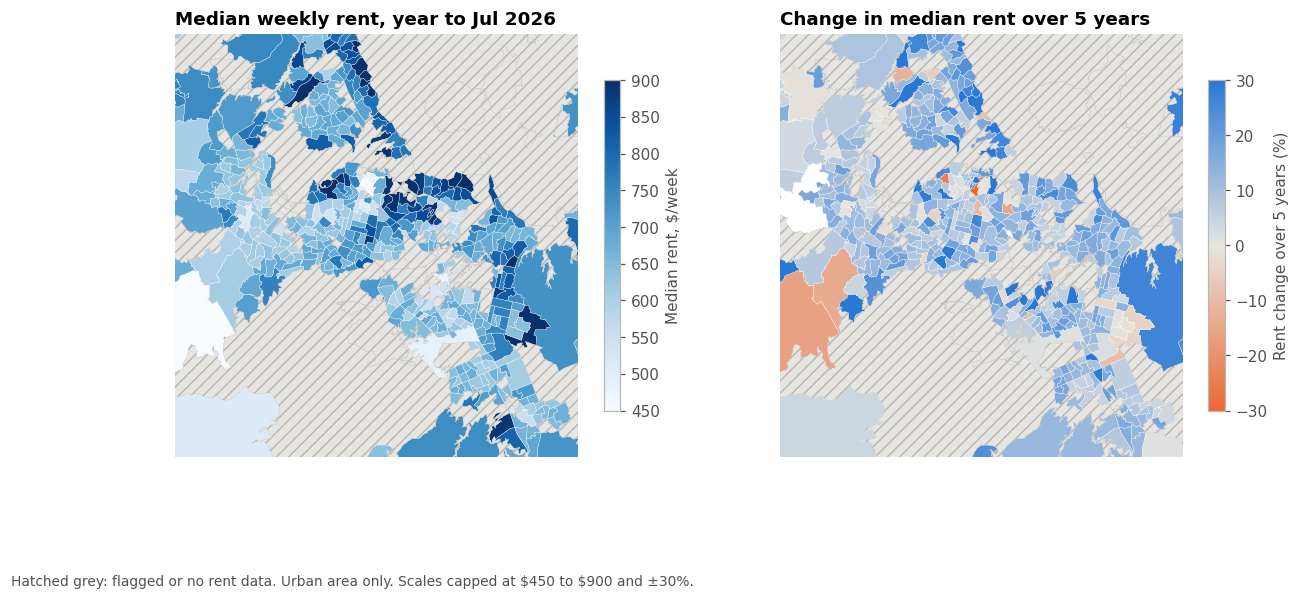

In [5]:
# STEP 3: MAPS
gm = geo[['sa2_code', 'geometry']].merge(m, on='sa2_code')
ok = gm[gm.analysis_ready & gm.median_rent_weekly.notna()]
bad = gm[~gm.index.isin(ok.index)]

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
ok.plot(column='median_rent_weekly', cmap=SEQ, vmin=450, vmax=900, ax=axes[0], edgecolor='white', linewidth=0.2,
        legend=True, legend_kwds={'label': 'Median rent, $/week', 'shrink': 0.6})
lim = 30
ok.plot(column='rent_change_5y_pct', cmap=DIV, vmin=-lim, vmax=lim, ax=axes[1], edgecolor='white', linewidth=0.2,
        legend=True, legend_kwds={'label': 'Rent change over 5 years (%)', 'shrink': 0.6})
for ax, t in zip(axes, [f'Median weekly rent, year to {latest:%b %Y}', 'Change in median rent over 5 years']):
    bad.plot(ax=ax, color='#e6e5e1', hatch='///', edgecolor=GREY, linewidth=0.2)
    ax.set_title(t); ax.set_axis_off(); ax.set_xlim(174.55, 175.0); ax.set_ylim(-37.1, -36.72)
fig.text(0.01, 0.02, r'Hatched grey: flagged or no rent data. Urban area only. Scales capped at \$450 to \$900 and ±30%.', color=MUTED, fontsize=9)
fig.savefig(VIZ / '02_rent_maps.png'); plt.show()

### Step 4: Did cheaper areas catch up?

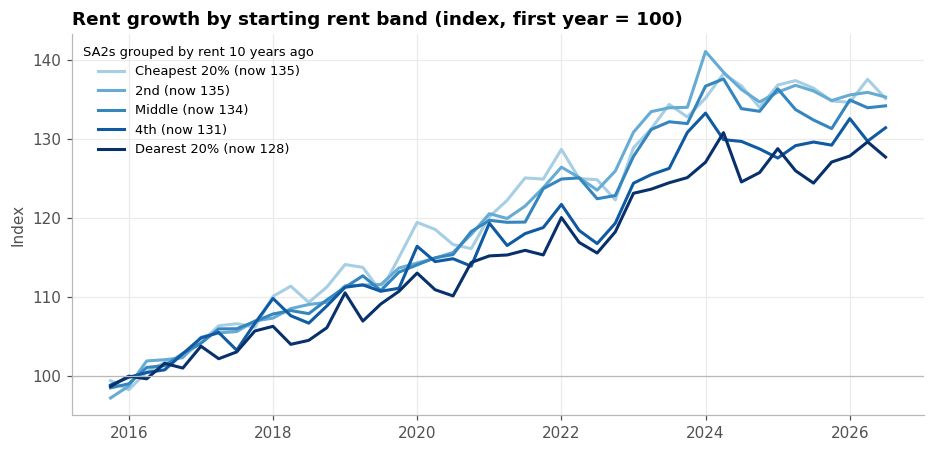

,SA2s,rent_10y_ago,rent_now,cagr_10y
band,,,,
Cheapest 20%,104,427.5,601.0,3.6
2nd,101,465.0,638.8,3.3
Middle,103,498.5,673.8,3.1
4th,102,542.2,703.9,2.7
Dearest 20%,103,625.0,817.5,2.6


In [6]:
# STEP 4: RENT BANDS. Split SA2s into five equal groups by their rent 10 years ago, then track each group's
# bond-weighted average rent, indexed to 100 at the start. Borrowed duplicates removed.
base = ready[ready.sa2_code.isin(unique_rent_sa2)].dropna(subset=['rent_10y_ago'])
base = base.assign(band=pd.qcut(base.rent_10y_ago, 5, labels=['Cheapest 20%', '2nd', 'Middle', '4th', 'Dearest 20%']))
start = latest - pd.DateOffset(years=11)
bt = ts_unique[ts_unique.quarter > start].merge(base[['sa2_code', 'band']], on='sa2_code')
bands = bt.groupby(['band', 'quarter'], observed=True).apply(lambda d: np.average(d.median_rent, weights=d.active_bonds),
                                                            include_groups=False).unstack(0)
idx = 100 * bands / bands.iloc[:4].mean()   # index: first 4 quarters = 100

colours = plt.get_cmap('Blues')(np.linspace(0.35, 1, 5))   # ordered bands -> one hue, light to dark
fig, ax = plt.subplots(figsize=(10, 4.5))
for col, colour in zip(idx.columns, colours):
    ax.plot(idx.index, idx[col], color=colour, lw=2, label=f'{col} (now {idx[col].iloc[-1]:.0f})')  # 5 lines: legend, no end labels
ax.axhline(100, color=GREY, lw=0.8)
ax.legend(frameon=False, loc='upper left', title='SA2s grouped by rent 10 years ago', title_fontsize=8.5, fontsize=8.5)
ax.set(title='Rent growth by starting rent band (index, first year = 100)', ylabel='Index')
fig.savefig(VIZ / '02_rent_bands.png'); plt.show()

summary = base.groupby('band', observed=True).agg(SA2s=('sa2_code', 'size'), rent_10y_ago=('rent_10y_ago', 'median'),
                                                   rent_now=('median_rent_weekly', 'median'), cagr_10y=('rent_cagr_10y_pct', 'median'))
summary.round(1)

In [7]:
# Side check: File 1's Auckland-wide line counted each borrowed parent once per child SA2. How much did that matter?
w = lambda d: np.average(d.median_rent, weights=d.active_bonds)
q_all = rent_ts[rent_ts.quarter == latest].pipe(w)
q_uni = ts_unique[ts_unique.quarter == latest].pipe(w)
print(f'Latest quarter, Auckland average: with duplicates ${q_all:.0f}/wk, without ${q_uni:.0f}/wk ({q_all - q_uni:+.0f})')

Latest quarter, Auckland average: with duplicates $662/wk, without $662/wk (-0)


### Step 5: Rent by dwelling type and bedrooms

All combinations, before masking ($/wk):
dwelling  House   Flat  Apartment
beds                             
1         634.0  437.0      480.0
2         572.0  547.0      616.0
3         699.0  473.0      621.0
4         863.0    NaN      293.0


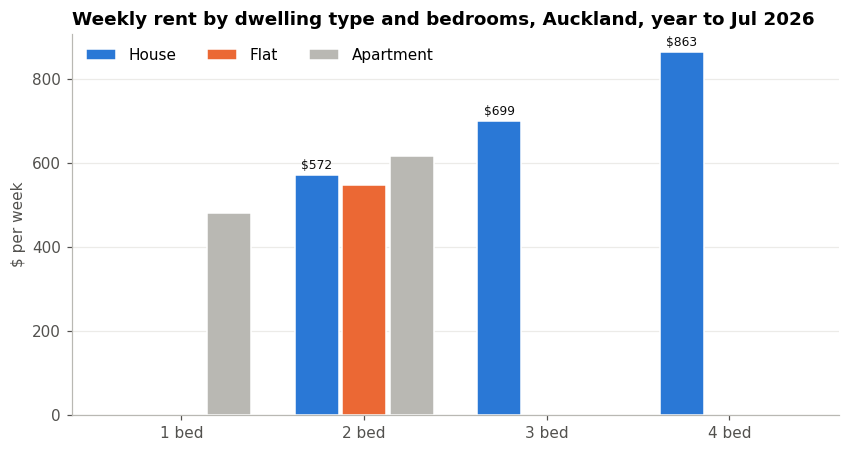

dwelling,House,Flat,Apartment
Active bonds,,,
1,21585,915,8094
2,11316,2961,7491
3,40707,42,585
4,12369,0,33


In [8]:
# STEP 5: DWELLING TYPE AND BEDROOMS from the raw MBIE file (build_master.py keeps only the 'ALL' rows)
# MBIE uses 2018 SA2 codes: the link is build_master.py's rent_source_sa2 (the 2018 SA2 each 2023 SA2 takes its rent from)
link = m[['sa2_code', 'rent_source_sa2']].rename(columns={'rent_source_sa2': 'sa2_2018'})

raw = pd.read_csv('data/rental/mbie_quarterly_sa2_2020_2026.csv', dtype=str,
                  usecols=['TimeFrame', 'Location Id', 'Dwelling Type', 'Number Of Beds', 'Median Rent', 'Active Bonds', 'Total Bonds'])
raw = pd.DataFrame({'quarter': pd.to_datetime(raw.TimeFrame, dayfirst=True),
                    'sa2_2018': pd.to_numeric(raw['Location Id'], errors='coerce'),
                    'dwelling': raw['Dwelling Type'], 'beds': raw['Number Of Beds'],
                    'median_rent': pd.to_numeric(raw['Median Rent'], errors='coerce'),
                    'active_bonds': pd.to_numeric(raw['Active Bonds'], errors='coerce'),
                    'lodged_bonds': pd.to_numeric(raw['Total Bonds'], errors='coerce')})   # NEW bonds lodged in the quarter
assert raw.quarter.max() == latest, 'raw MBIE file and cleaned series disagree on the latest quarter'
yr_all = raw[(raw.quarter > latest - pd.DateOffset(years=1)) & raw.sa2_2018.isin(link.sa2_2018)]   # keeps suppressed quarters' lodgements
yr = yr_all.dropna(subset=['median_rent', 'active_bonds'])

# Auckland-wide: bond-weighted average of 2018-SA2 medians (each 2018 SA2 once, so no borrowed duplicates here)
types = ['House', 'Flat', 'Apartment']
sel = yr[yr.dwelling.isin(types) & yr.beds.isin(['1', '2', '3', '4'])]
by_type = sel.groupby(['dwelling', 'beds']).apply(lambda d: pd.Series({'rent': np.average(d.median_rent, weights=d.active_bonds),
                                                                          'bonds': d.sort_values('quarter').groupby('sa2_2018').active_bonds.last().sum()}),
                                                   include_groups=False).reset_index()
pivot = by_type.pivot(index='beds', columns='dwelling', values='rent')[types]
bonds = by_type.pivot(index='beds', columns='dwelling', values='bonds')[types].fillna(0)
print('All combinations, before masking ($/wk):'); print(pivot.round(0).to_string())
# Hide thin cells (under 1,000 bonds) and 1-bed houses, whose bedroom count looks mis-recorded at source (see note below)
pivot = pivot.where(bonds >= 1000); pivot.loc['1', 'House'] = np.nan

colours = [BLUE, ORANGE, GREY]  # categorical slots in fixed order
fig, ax = plt.subplots(figsize=(9, 4.5))
xs = np.arange(len(pivot)); wbar = 0.26
for i, (t, colour) in enumerate(zip(types, colours)):
    ax.bar(xs + (i - 1) * wbar, pivot[t], width=wbar - 0.02, color=colour, edgecolor='white', linewidth=1, label=t)
ax.bar_label(ax.containers[0], labels=[f'${v:.0f}' if np.isfinite(v) else '' for v in pivot['House']],
             fontsize=8, color=INK, padding=2)  # label houses only, not every bar
ax.set_xticks(xs, [f'{b} bed' for b in pivot.index]); ax.set_xlim(-0.6, len(xs) - 0.4)
ax.legend(frameon=False, ncols=3, loc='upper left')
ax.grid(axis='x', visible=False)
ax.set(title=f'Weekly rent by dwelling type and bedrooms, Auckland, year to {latest:%b %Y}', ylabel='$ per week')
fig.savefig(VIZ / '02_rent_by_type_beds.png'); plt.show()
bonds.astype(int).rename_axis('Active bonds')

**Reading this:** the bedroom split is the weakest part of the MBIE data. Nationally, MBIE records about 68,000
"1-bedroom houses" with a higher median rent than 2-bedroom houses. That points to bedroom counts being entered
wrongly or defaulted when bonds are lodged, so 1-bed houses are left off the chart. Cells with fewer than 1,000 bonds
(for example 4-bedroom apartments, often let by the room to students) are left off too. 3-bedroom houses are the
largest and cleanest category, so they are used below.

**Official warning:** Tenancy Services says bonds recorded as one-bedroom have risen sharply and may not reflect the real
bedroom count, so one-bedroom counts and rents should be read with caution
([rental bond data notes](https://www.tenancy.govt.nz/about-tenancy-services/data-and-statistics/rental-bond-data/)). Every
1-bed row of `rent_by_type_sa2.csv` carries this in `data_note`. MBIE also rounds counts to base 3 and suppresses figures
for fewer than 5 bonds.

**SA2 estimates by dwelling type are thin.** A 3-bed house rent for one rent area rests on a median of 21 new lodgements over
the year, even where there are hundreds of active bonds. So the export carries new lodgements over the 4 quarters, the lowest
and highest quarterly median, and two checks: `flag_thin_sample` (fewer than 30 new lodgements) and `flag_unstable_rent`
(highest quarterly median over 1.5× the lowest). In `rent_metrics_by_sa2.csv`, `flag_verify_3bed_house` is either check.
- The two cheapest 3-bed house figures below, Tāmaki (\$423) and Point England (\$507), are the two most unstable: their
  quarterly medians run from \$166–180 to \$650–713. Verify them against another source before using them as a rent level.

In [9]:
# 3-bedroom house rent by SA2: the standard family rental. MBIE leaves the median blank when too few bonds were lodged.
h3 = yr[(yr.dwelling == 'House') & (yr.beds == '3')].sort_values('quarter').groupby('sa2_2018').agg(
    rent_3bed_house=('median_rent', 'mean'), bonds_3bed_house=('active_bonds', 'last'))
# Same measure for every dwelling type x bedrooms combination, so a budget screen can cap the rent of the home it asks for.
# quarters = how many of the last 4 quarters had a published median (MBIE suppresses thin cells)
# lodged_bonds_4q = NEW bonds lodged over the 4 quarters: the sample behind the medians. active_bonds = all tenancies held,
# which is far larger and NOT the sample. Two checks flag an estimate for verification before it is used as a budget match:
#   thin sample: fewer than 30 new lodgements over the 4 quarters (the same minimum File 6 uses)
#   unstable: the highest published quarterly median is over 1.5x the lowest (99% of 3-bed house rent areas are under 1.41)
MIN_LODGED_4Q, MAX_SWING = 30, 1.5
ONE_BED_NOTE = ('Tenancy Services (Nov 2026): a sharp rise in bonds recorded as one-bedroom may not reflect the real bedroom '
                'count; read one-bedroom counts and rents with caution. tenancy.govt.nz rental bond data')
by_type = (yr.sort_values('quarter').groupby(['sa2_2018', 'dwelling', 'beds'])
             .agg(rent=('median_rent', 'mean'), active_bonds=('active_bonds', 'last'), quarters=('quarter', 'size'),
                  rent_min_quarter=('median_rent', 'min'), rent_max_quarter=('median_rent', 'max')).reset_index()
             .join(yr_all.groupby(['sa2_2018', 'dwelling', 'beds']).lodged_bonds.sum(min_count=1).rename('lodged_bonds_4q'),
                   on=['sa2_2018', 'dwelling', 'beds']))
by_type['flag_thin_sample'] = ~(by_type.lodged_bonds_4q >= MIN_LODGED_4Q)
by_type['flag_unstable_rent'] = by_type.rent_max_quarter > MAX_SWING * by_type.rent_min_quarter
by_type['data_note'] = np.where(by_type.beds == '1', ONE_BED_NOTE, '')
h = by_type[(by_type.dwelling == 'House') & (by_type.beds == '3')]
print(f'3-bed house rent areas: {len(h)} | thin sample: {h.flag_thin_sample.sum()} | unstable: {h.flag_unstable_rent.sum()} | '
      f'median new lodgements over 4 quarters: {h.lodged_bonds_4q.median():.0f}')
print('Unstable 3-bed house estimates:')
print(h[h.flag_unstable_rent][['sa2_2018', 'rent', 'rent_min_quarter', 'rent_max_quarter', 'lodged_bonds_4q', 'active_bonds']].to_string(index=False))
m = m.merge(link, on='sa2_code', how='left').join(h3, on='sa2_2018').drop(columns='sa2_2018')
assert len(m) == 633 and m.sa2_code.is_unique
v = by_type[(by_type.dwelling == 'House') & (by_type.beds == '3')].set_index('sa2_2018')
m['lodged_3bed_house_4q'] = m.rent_source_sa2.map(v.lodged_bonds_4q)   # new lodgements; bonds_3bed_house is ACTIVE bonds
m['flag_verify_3bed_house'] = m.rent_source_sa2.map(v.flag_thin_sample | v.flag_unstable_rent)   # NaN where no estimate
ready = m[m.analysis_ready]
print(f'SA2s with a 3-bed house rent: {m.rent_3bed_house.notna().sum()} of {len(m)}')
print(f'Median SA2 3-bed house rent: ${ready.rent_3bed_house.median():.0f}/wk vs all dwellings ${ready.median_rent_weekly.median():.0f}/wk')
c = ['sa2_name', 'rent_3bed_house', 'lodged_3bed_house_4q', 'bonds_3bed_house', 'flag_verify_3bed_house', 'median_rent_weekly', 'flag_borrowed_rent']
r3 = ready.dropna(subset=['rent_3bed_house']).drop_duplicates('rent_source_sa2')
print('Cheapest and dearest 3-bed house rents (borrowed duplicates shown once):')
pd.concat([r3.nsmallest(8, 'rent_3bed_house')[c], r3.nlargest(8, 'rent_3bed_house')[c]]).round(0)

3-bed house rent areas: 373 | thin sample: 261 | unstable: 3 | median new lodgements over 4 quarters: 21
Unstable 3-bed house estimates:
 sa2_2018       rent  rent_min_quarter  rent_max_quarter  lodged_bonds_4q  active_bonds
 146300.0 507.250000             166.0             713.0               30           351
 147000.0 422.750000             180.0             660.0               51           357
 147100.0 606.333333             434.0             695.0               24           177
SA2s with a 3-bed house rent: 438 of 633
Median SA2 3-bed house rent: $698/wk vs all dwellings $672/wk
Cheapest and dearest 3-bed house rents (borrowed duplicates shown once):


,sa2_name,rent_3bed_house,lodged_3bed_house_4q,bonds_3bed_house,flag_verify_3bed_house,median_rent_weekly,flag_borrowed_rent
516,Tamaki East,423.0,51.0,357.0,True,580.0,True
345,Point England North,507.0,30.0,351.0,True,535.0,True
125,Hamilton Estate,587.0,24.0,93.0,True,565.0,False
281,Northcote Tuff Crater,590.0,6.0,60.0,True,736.0,False
4,Cape Rodney,595.0,12.0,60.0,True,611.0,False
91,Helensville,595.0,6.0,57.0,True,633.0,False
333,Henderson Valley Park,595.0,6.0,72.0,True,591.0,False
390,Favona West,595.0,6.0,72.0,True,596.0,False
376,Herne Bay,1500.0,6.0,51.0,True,769.0,False
180,Saint Marys Bay,1123.0,6.0,57.0,True,718.0,False


### Step 6: Affordability, rent against household income

Median area ratio, annualised new-tenancy rent / all-household median income (analysis-ready): 29.4%
SA2s above 30% (a common stress line): 259 of 585


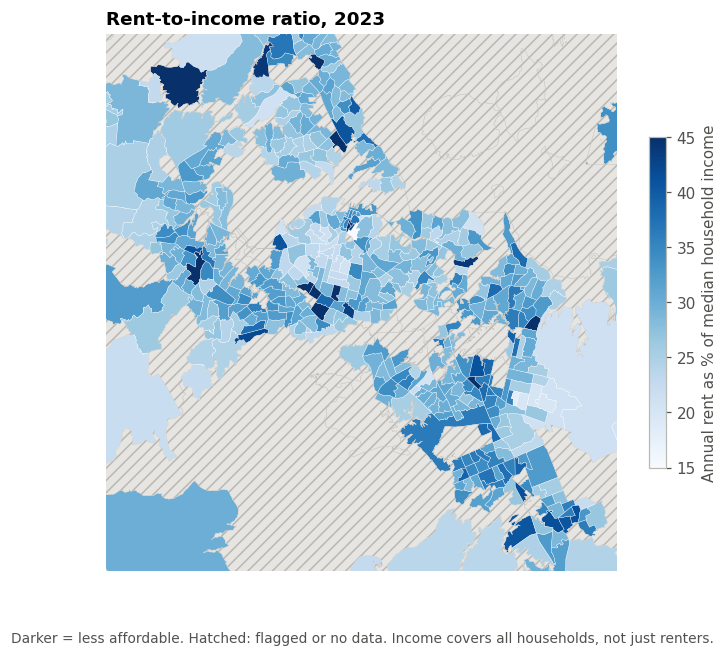

Least and most affordable:


,sa2_name,rent_2023_weekly,median_household_income,rent_to_income_pct,pct_owner_occupied
261,Akoranga,692.7,45100.0,79.9,61.6
135,Henderson Central,545.0,40300.0,70.3,58.5
209,Orewa South,728.8,55500.0,68.3,77.0
407,Windsor Park,772.5,71400.0,56.3,75.0
192,Orewa Central,605.0,59800.0,52.6,64.2
352,Dannemora North-Shamrock Park,950.0,98800.0,50.0,85.9
93,Ostend,714.3,74900.0,49.6,72.9
625,Symonds Street West,483.8,51600.0,48.8,15.3
542,Grafton,292.5,122100.0,12.5,34.3
612,Ara Hill,577.0,177500.0,16.9,92.3


In [10]:
# STEP 6: RENT-TO-INCOME = annual rent / median household income x 100.
# Census income is for 2023, so rent is taken over the same 2023 quarters to keep the years matched.
r23 = rent_ts[rent_ts.quarter.dt.year == 2023].groupby('sa2_code').median_rent.mean().rename('rent_2023_weekly')
m = m.join(r23, on='sa2_code')
m['rent_to_income_pct'] = 100 * m.rent_2023_weekly * 52 / m.median_household_income
ready = m[m.analysis_ready]
print(f'Median area ratio, annualised new-tenancy rent / all-household median income (analysis-ready): {ready.rent_to_income_pct.median():.1f}%')
print(f'SA2s above 30% (a common stress line): {(ready.rent_to_income_pct > 30).sum()} of {ready.rent_to_income_pct.notna().sum()}')

gm = geo[['sa2_code', 'geometry']].merge(m, on='sa2_code')
ok = gm[gm.analysis_ready & gm.rent_to_income_pct.notna()]; bad = gm[~gm.index.isin(ok.index)]
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ok.plot(column='rent_to_income_pct', cmap=SEQ, vmin=15, vmax=45, ax=ax, edgecolor='white', linewidth=0.2,
        legend=True, legend_kwds={'label': 'Annual rent as % of median household income', 'shrink': 0.6})
bad.plot(ax=ax, color='#e6e5e1', hatch='///', edgecolor=GREY, linewidth=0.2)
ax.set_title('Rent-to-income ratio, 2023'); ax.set_axis_off(); ax.set_xlim(174.55, 175.0); ax.set_ylim(-37.1, -36.72)
fig.text(0.01, 0.02, 'Darker = less affordable. Hatched: flagged or no data. Income covers all households, not just renters.', color=MUTED, fontsize=9)
fig.savefig(VIZ / '02_affordability_map.png'); plt.show()

c = ['sa2_name', 'rent_2023_weekly', 'median_household_income', 'rent_to_income_pct', 'pct_owner_occupied']
print('Least and most affordable:')
pd.concat([ready.nlargest(8, 'rent_to_income_pct')[c], ready.nsmallest(8, 'rent_to_income_pct')[c]]).round(1)

**Reading this:** the measure is an **area-level ratio**: annualised 2023 new-tenancy (bond) median rent divided by the SA2's
median income for *all* households. It is not the share of income renters actually pay. Census household income covers owners as well as renters, and renters usually earn less, so
the ratio for a typical renter is higher than shown. The extremes are mostly about who lives there, not about rent:
Orewa and Henderson Central have many retirees on low incomes who own their homes, which pushes the ratio up, and
Grafton's low ratio comes from student rooms with low rents. Read this ratio next to `pct_owner_occupied`, and don't rank on it alone.

### Step 7: Save outputs

In [11]:
# STEP 7: SAVE
keep = ['sa2_code', 'sa2_name', 'median_rent_weekly', 'active_bonds', 'rent_1y_ago', 'rent_5y_ago', 'rent_10y_ago',
        'rent_change_1y_pct', 'rent_change_5y_pct', 'rent_change_10y_pct', 'rent_cagr_10y_pct',
        'rent_3bed_house', 'bonds_3bed_house', 'lodged_3bed_house_4q', 'flag_verify_3bed_house', 'rent_2023_weekly', 'median_household_income', 'rent_to_income_pct',
        'rent_source_sa2', 'flag_borrowed_rent', 'analysis_ready']
out = CLEAN / 'rent_metrics_by_sa2.csv'
m[keep].round(2).to_csv(out, index=False)
check = pd.read_csv(out)
assert len(check) == 633 and check.sa2_code.is_unique
print(f'Saved {out} ({check.shape[0]} rows, {check.shape[1]} columns)')
# Long file: one row per SA2 x dwelling type x bedrooms (last 4 quarters), for budget screens on the home actually wanted
out2 = CLEAN / 'rent_by_type_sa2.csv'
link.merge(by_type, on='sa2_2018').rename(columns={'sa2_2018': 'rent_source_sa2'}).round(2).to_csv(out2, index=False)
check2 = pd.read_csv(out2)
assert not check2.duplicated(['sa2_code', 'dwelling', 'beds']).any()
print(f'Saved {out2} ({len(check2):,} rows: SA2 x dwelling x bedrooms)')
print('Charts:', ', '.join(sorted(p.name for p in VIZ.glob('02_*.png'))))

Saved data\clean\rent_metrics_by_sa2.csv (633 rows, 21 columns)
Saved data\clean\rent_by_type_sa2.csv (5,022 rows: SA2 x dwelling x bedrooms)
Charts: 02_affordability_map.png, 02_rent_bands.png, 02_rent_by_type_beds.png, 02_rent_maps.png


# File 2: Rental Analysis - Summary

## What we did
Built rent growth over 1, 5 and 10 years for every SA2 from the quarterly MBIE series, mapped rent level and change,
tracked whether cheap areas caught up, split rent by dwelling type and bedrooms from the raw MBIE file, and set rent
against 2023 census household income. Output: `data/clean/rent_metrics_by_sa2.csv`.

## Checks
- Current rent and 5-year change recomputed here match `build_master.py` exactly (assert in Step 2).
- 527 distinct rent areas (one per MBIE source SA2, `rent_source_sa2`). Removing them changed the latest Auckland average by
  less than \$1, so File 1's Auckland line is not distorted by the duplicates.
- 468 SA2s have all 40 quarters of the last 10 years; 53 have fewer than 30 (small or new areas).

## Key findings
1. **Rent has stalled.** The median SA2 changed 0.0% over the last year, after +12% over 5 years and +35% over 10
   (3.0% a year). This matches File 1's Auckland-wide flattening since 2024.
2. **Cheaper areas caught up.** SA2s in the cheapest fifth 10 years ago grew 3.6% a year (median SA2), against 2.6% for
   the dearest fifth. On the band chart the bottom three bands are up about 35% and the dearest band 28%. Most of the gap opened
   in 2020–2024, and all bands have been flat since 2024.
3. **The biggest movers are mix changes, not price moves.** Ōtara Central +140%, Grafton −39%. Check bond counts and
   dwelling type before reading a big change as a trend.
4. **A 3-bedroom house costs about \$700/wk** (Auckland bond-weighted average \$699; median SA2 \$698). The cheapest
   areas with a 3-bed house figure are around \$590–600 (Hamilton Estate, Henderson Valley Park, Helensville, Tamakae), and Herne Bay
   is the dearest at \$1,500. 438 of 633 SA2s have a 3-bed house figure.
5. **Affordability is tight.** The median area ratio of annualised new-tenancy rent to all-household median income is 29.4% (2023), and 259 of 585
   SA2s are above 30%. The highest ratios are retiree and student areas, where household income says little about renters.

## What this means for the dashboard
- Rent page: map with a 1/5/10-year toggle, an SA2 time-series chart, and a 3-bed house figure next to the all-dwelling median.
- Always show bond count next to a rent figure, and label borrowed-rent SA2s.
- Affordability: show alongside tenure (owner-occupied %), never as a stand-alone ranking.

## Limitations
- Rents are medians of new bonds lodged, so they lag sitting tenants' rents and shift when the dwelling mix changes.
- The bedroom field in MBIE data is unreliable for houses (the 1-bed house anomaly); only 3-bed houses are used per SA2.
- Income is 2023 census for all households; there is no renter-only income by SA2. Actual rental stress (rent paid against
  renters' own income) stays open until matched renter income and rent data is available.
- The 3-bed house figure is by 2018 SA2, so split SA2s share it, like the all-dwelling rent.

## Next
- **File 3: Area profiles**: demographics and amenities against rent and CV (add census religion here if wanted).
- **File 4: Risk & value screen**: combine `master_flagged.csv` and `rent_metrics_by_sa2.csv`.